# LeetCode #169: Majority Element

https://leetcode.com/problems/majority-element/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Hash Map | O(n) | O(n) |
| Sort | O(n log n) | O(1) |
| Boyer-Moore Voting ★ | O(n) | O(1) |

## Understanding the Methods
### Hash Map
Count occurrences of each element; return the one with count > n/2.

### Sort
The majority element always occupies the middle position when sorted.

### Optimal: Boyer-Moore Voting ★
Maintain a candidate and a count. For each element: if count is 0, set candidate to current element. If element matches candidate, increment count; else decrement. The majority element (appearing > n/2 times) always survives as the final candidate.

## Solutions
### C#

In [ ]:
public class Solution {
    public int MajorityElement(int[] nums) {
        int candidate = 0, count = 0;
        foreach (int num in nums) {
            if (count == 0) candidate = num;
            count += num == candidate ? 1 : -1;
        }
        return candidate;
    }
}

### Python

In [ ]:
from typing import List

class Solution:
    def majorityElement(self, nums: List[int]) -> int:
        candidate, count = 0, 0
        for num in nums:
            if count == 0:
                candidate = num
            count += 1 if num == candidate else -1
        return candidate

### Go

In [ ]:
package main

import "fmt"

func majorityElement(nums []int) int {
    candidate, count := 0, 0
    for _, num := range nums {
        if count == 0 {
            candidate = num
        }
        if num == candidate {
            count++
        } else {
            count--
        }
    }
    return candidate
}

func main() {
    fmt.Println(majorityElement([]int{3, 2, 3}))             // 3
    fmt.Println(majorityElement([]int{2, 2, 1, 1, 1, 2, 2})) // 2
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn majority_element(nums: Vec<i32>) -> i32 {
        let (mut candidate, mut count) = (0i32, 0i32);
        for &num in &nums {
            if count == 0 { candidate = num; }
            count += if num == candidate { 1 } else { -1 };
        }
        candidate
    }
}

## Example Scenarios

### 1. Common Case — Clear Majority
**Input:** `nums = [3,2,3]`
Candidate starts at $3$ (count $1$), dips to $0$ on the $2$, then $3$ re-takes the lead. Majority is $3$ (appears $2 > 3/2$ times).

### 2. Slightly Complex — Candidate Switches
**Input:** `nums = [2,2,1,1,1,2,2]`
The count for $2$ falls to $0$, letting $1$ briefly become candidate, but the trailing $2$s overrule it. Answer $2$ ($4/7$).

### 3. Edge Case: Time Factor — One Pass Over a Long Array
**Input:** `nums = [1,1,1,2,3,4,1,1,1]`
A single linear scan suffices; scattered $1$s ($6/9$) keep the running balance positive. Output $1$.

### 4. Edge Case: Space Factor — O(1), Single Element
**Input:** `nums = [5]`
Only a candidate and an integer count are stored — no hash map. The lone element is trivially the majority: $5$.

### 5. Almost-Impossible but Plausible — Repeated Resets
**Input:** `nums = [7,1,7,2,7,3,7]`
The count keeps resetting to $0$ as $7$ alternates with distinct others, yet $7$ ($4/7$) always reclaims the candidacy. Output $7$.


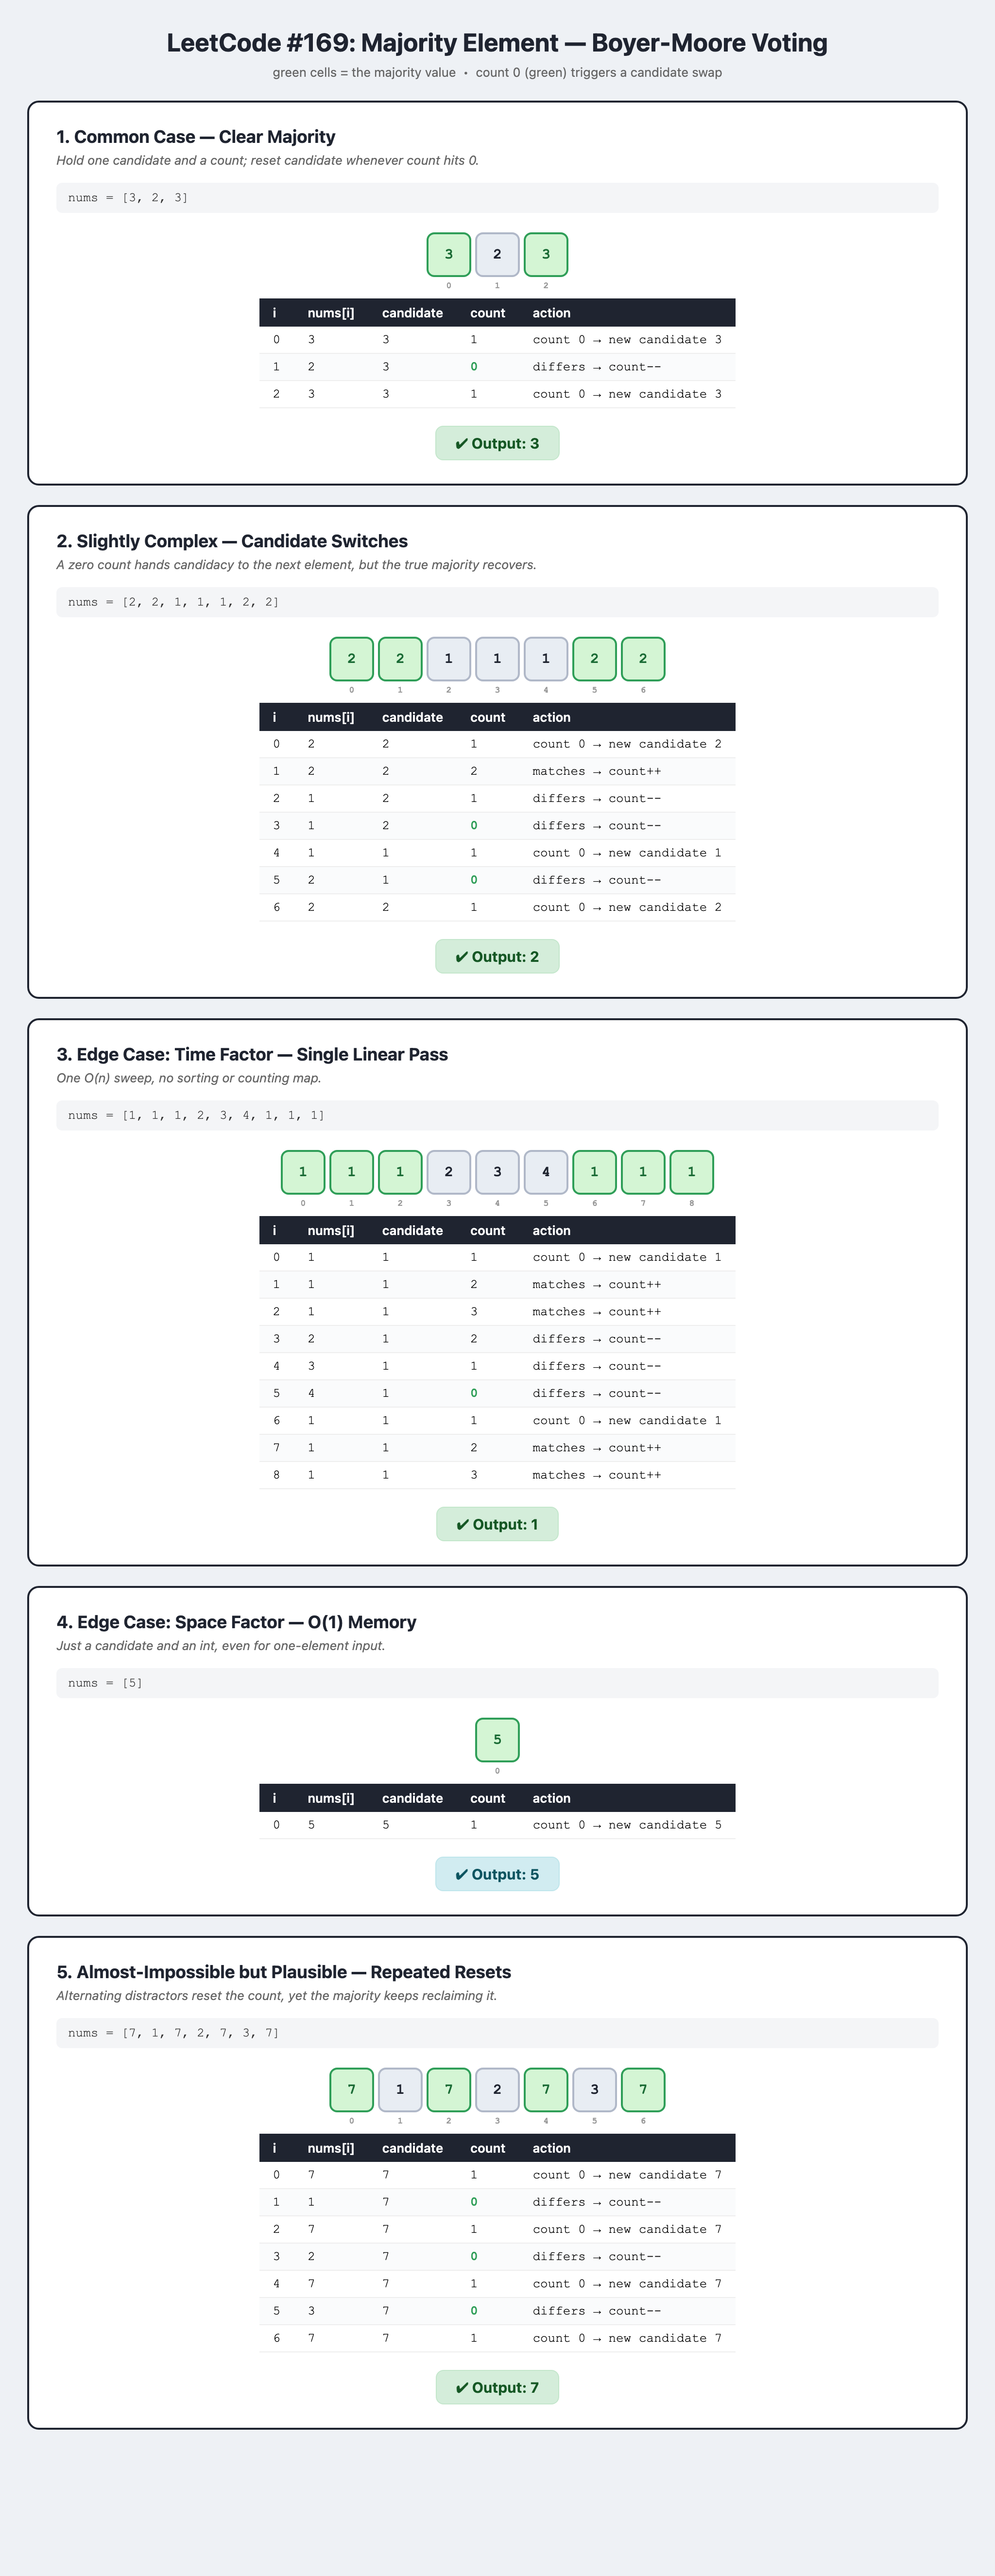